# Heart Disease Prediction using Machine Learning
**Supervised classification · Four-day student project**

**Question:** Can clinical features predict a heart disease label? This is an educational exercise, not a diagnostic tool.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
from pathlib import Path

# The notebook and dataset are in the same project folder.
data_path = Path("heart.xls")
df = pd.read_csv(data_path)
display(df.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Day 1 — Dataset understanding
The outcome is `HeartDisease`: 1 indicates a record labeled heart disease, 0 means no heart disease. All other 11 columns are potential predictive features.

In [2]:
print('Rows and columns:', df.shape)
display(df.dtypes.to_frame('dtype'))
print('Duplicates:', df.duplicated().sum())
print('Blank cells:', df.isna().sum().sum())
display(df['HeartDisease'].value_counts().rename(index={0:'No disease',1:'Disease'}))

Rows and columns: (918, 12)


,dtype
Age,int64
Sex,object
ChestPainType,object
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,object
MaxHR,int64
ExerciseAngina,object
Oldpeak,float64


Duplicates: 0
Blank cells: 0


Disease       508
No disease    410
Name: HeartDisease, dtype: int64

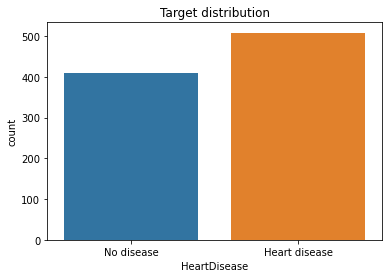

In [3]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df,x='HeartDisease',ax=ax)
ax.set(title='Target distribution',xticks=[0,1],xticklabels=['No disease','Heart disease'])
plt.show()

## Day 2 — Cleaning and feature preparation
Zero resting blood pressure and cholesterol values are physiologically implausible; convert them to missing values. Crucially, median imputation and encoding happen in training-fold pipelines to avoid leakage.

In [4]:
df = df.drop_duplicates().copy()
for col in ['RestingBP','Cholesterol']:
    print(col, 'zeros:', (df[col] == 0).sum())
    df.loc[df[col].eq(0),col] = np.nan
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']
num_cols = ['Age','RestingBP','Cholesterol','FastingBS','MaxHR','Oldpeak']
cat_cols = [x for x in X.columns if x not in num_cols]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
print('Training:',X_train.shape,'Test:',X_test.shape)

RestingBP zeros: 1
Cholesterol zeros: 172
Training: (734, 11) Test: (184, 11)


## Day 3 — Models and cross-validation
We compare a no-skill dummy model, Logistic Regression and Random Forest using the same 5-fold stratified training-only validation scheme.

In [5]:
preprocess=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scaler',StandardScaler())]),num_cols),
 ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('encoder',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)
])
models={
 'Majority baseline':DummyClassifier(strategy='most_frequent'),
 'Logistic Regression':Pipeline([('preprocess',preprocess),('classifier',LogisticRegression(max_iter=2000,random_state=42))]),
 'Random Forest':Pipeline([('preprocess',preprocess),('classifier',RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))])
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
rows=[]
for name, model in models.items():
 s=cross_validate(model,X_train,y_train,cv=cv,scoring=['accuracy','f1','recall','roc_auc'])
 rows.append(dict(model=name, **{metric:round(s['test_'+metric].mean(),3) for metric in ['accuracy','f1','recall','roc_auc']}))
score_table=pd.DataFrame(rows)
display(score_table)

,model,accuracy,f1,recall,roc_auc
0,Majority baseline,0.553,0.712,1.000,0.500
1,Logistic Regression,0.857,0.873,0.887,0.928
2,Random Forest,0.853,0.871,0.894,0.926


## Day 4 — Tuning and final test evaluation
Only the training data participates in GridSearchCV. We choose the best model from cross-validation, then use the test set once for a final unbiased estimate.

In [6]:
grid=GridSearchCV(models['Random Forest'],{
 'classifier__n_estimators':[100,200],
 'classifier__max_depth':[5,None],
 'classifier__min_samples_leaf':[1,3]
},scoring='roc_auc',cv=cv,n_jobs=-1)
grid.fit(X_train,y_train)
print('Best RF cross-validation AUC:',round(grid.best_score_,3))
print('Best parameters:',grid.best_params_)
strongest=score_table.loc[score_table.model.isin(['Logistic Regression','Random Forest'])].sort_values('roc_auc',ascending=False).iloc[0]
if grid.best_score_ > strongest.roc_auc:
    selected=grid.best_estimator_
    selected_name='Tuned Random Forest'
else:
    selected_name=strongest.model
    selected=models[selected_name].fit(X_train,y_train)
print('Selected based on training CV:',selected_name)
pred=selected.predict(X_test)
prob=selected.predict_proba(X_test)[:,1]
print(classification_report(y_test,pred))
print('ROC-AUC:',round(roc_auc_score(y_test,prob),3))

Best RF cross-validation AUC: 0.933
Best parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Selected based on training CV: Tuned Random Forest
              precision    recall  f1-score   support

           0       0.92      0.83      0.87        82
           1       0.87      0.94      0.91       102

    accuracy                           0.89       184
   macro avg       0.90      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184

ROC-AUC: 0.938


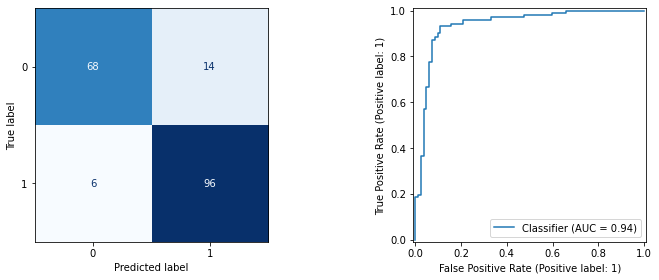

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=axes[0],cmap='Blues',colorbar=False)
RocCurveDisplay.from_predictions(y_test,prob,ax=axes[1])
plt.tight_layout()
plt.show()

## Key findings and limitations
Inspect ROC-AUC, recall, and confusion matrix alongside accuracy. False negatives are relevant for a screening-style problem, but threshold selection requires clinical context. Dataset size, historical sourcing, missing value assumptions, and lack of independent clinical validation prevent real-world medical use.

**Next:** external validation, probability calibration, fairness checks and clinician-led evaluation.